# Groups, moments and finite-size networks

This notebook connects the project's shared group-action model to observable return and volume moments. It uses `src/econophysics/model.py` and the frozen finite-size scan.

**Questions:** Why does a group contribute its size squared? Why can mean activity remain unchanged while risk changes?

中文：本 notebook 用项目共用代码解释群体动作、规模平方和，以及相同平均成交量下的不同风险。

In [1]:
from pathlib import Path
import sys, os, csv
ROOT = Path.cwd()
while not (ROOT / "src/econophysics").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook inside the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
def read_table(name):
    with (ROOT / "results/tables" / name).open() as f:
        return list(csv.DictReader(f))
print("Repository found. Shared implementation and frozen tables are available.")

Matplotlib is building the font cache; this may take a moment.


Repository found. Shared implementation and frozen tables are available.


## 1. One action for each group

For group $C$, $\xi_C\in\{-1,0,+1\}$ has probabilities $q/2,1-q,q/2$. Different groups choose independently. The implementation stores each directional probability as `a=q/2`.

$$r=\frac{\lambda}{N}\sum_Cs_C\xi_C,\qquad V=u\sum_Cs_C|\xi_C|.$$

Fixing the graph, the mixed terms vanish because $\mathbb E\xi_C=0$. Therefore

$$\operatorname{Var}(r\mid H)=q(\lambda/N)^2\sum_Cs_C^2.$$

In [2]:
from econophysics.model import Parameters, conditional_moments, aggregate_orders
p = Parameters(n=100, rho=0, a=0.1, lambda_impact=0.02, unit_order=1)
independent = conditional_moments([1] * 100, p)
coordinated = conditional_moments([10] * 10, p)
for name, result in [("Independent", independent), ("Ten groups of ten", coordinated)]:
    print(f"{name:20s} E[V]={result['mean_V']:.0f}, Var(V)={result['var_V']:.0f}, S2={result['s2']}")
assert np.isclose(independent['mean_V'], coordinated['mean_V'])
assert np.isclose(coordinated['var_V'] / independent['var_V'], 10)
assert np.isclose(coordinated['var_r'] / independent['var_r'], 10)

Independent          E[V]=20, Var(V)=16, S2=100
Ten groups of ten    E[V]=20, Var(V)=160, S2=1000


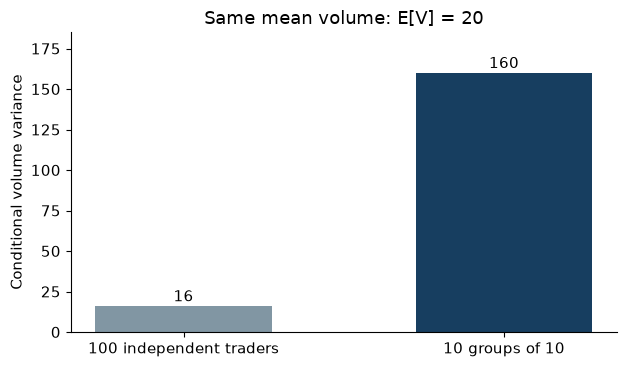

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
values = [independent["var_V"], coordinated["var_V"]]
ax.bar(["100 independent traders", "10 groups of 10"], values, color=["#8196a3", "#173e60"], width=0.55)
for i, value in enumerate(values): ax.text(i, value + 3, f"{value:.0f}", ha="center")
ax.set(ylabel="Conditional volume variance", ylim=(0, 185), title="Same mean volume: E[V] = 20")
fig.tight_layout(); plt.show()

## 2. Check the executed quantities

With one four-person group, buying produces $r=\lambda$ and $V=4u$; inactivity gives zero. These calls exercise the same implementation used in the project.

In [4]:
p4 = Parameters(n=4, rho=1, a=0.1)
for action in [-1, 0, 1]:
    print(action, aggregate_orders([4], [action], p4))
assert aggregate_orders([4], [0], p4) == (0.0, 0.0)

-1 (-0.02, 4.0)
0 (0.0, 0.0)
1 (0.02, 4.0)


## 3. Read the finite-size network experiment

The expected mean degree $c$ is stored as `rho`. The infinite sparse-ER threshold is $c=1$; the original experiment compares finite networks with 40 graph draws per setting.

The largest-group fraction is a finite statistic. It is distinct from the infinite-limit giant fraction $S$ and from the finite-cluster statistic that excludes one largest group.

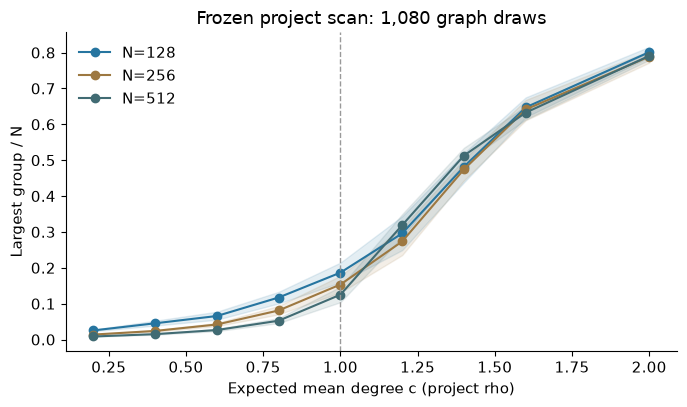

In [5]:
rows = read_table("simulation_study_v1/phase_summary.csv")
assert len(rows) == 27
assert sum(int(r["graphs"]) for r in rows) == 1080
fig, ax = plt.subplots(figsize=(7, 4.2))
for n, color in [(128, "#2675a0"), (256, "#9d7841"), (512, "#416b73")]:
    rr = sorted([r for r in rows if int(r["n"]) == n], key=lambda r: float(r["rho"]))
    x = np.array([float(r["rho"]) for r in rr])
    mean = np.array([float(r["largest_fraction_mean"]) for r in rr])
    lo = np.array([float(r["largest_fraction_ci_low"]) for r in rr])
    hi = np.array([float(r["largest_fraction_ci_high"]) for r in rr])
    ax.plot(x, mean, "o-", label=f"N={n}", color=color)
    ax.fill_between(x, lo, hi, alpha=0.12, color=color)
ax.axvline(1, color="0.6", linestyle="--", linewidth=1)
ax.set(xlabel="Expected mean degree c (project rho)", ylabel="Largest group / N", title="Frozen project scan: 1,080 graph draws")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## What this establishes

The grouping controls a computable fluctuation contribution through $S_2$. The finite scan shows how ER connectivity changes group structure. The separate finite-return tail test is retained in the report and figure F05.

**Continue:** [Inversion and identification limits](02_inference_and_identity.ipynb).